# Bipedal locomotion, part 4: gaits

*Contact scheduling drives the whole-body controller.*

In [Part 3](locomotion_part_3_wbc.ipynb) we built a whole-body QP that, given a
**fixed** set of feet on the ground, solved for joint accelerations and torques
that track posture, centre-of-mass, and momentum tasks while respecting each
stance foot's no-slip constraint. But a walking robot does not keep a fixed
contact set: feet lift and land in a repeating rhythm. That rhythm is the
**gait**, and the object that encodes it is a *contact schedule*.

This notebook closes the loop between the two. A gait is nothing more than a
periodic, per-foot "is this foot on the ground right now?" signal. Feed that
signal into the WBC and its contact set becomes **time-varying for free**: a
stance foot's contact task switches on, a swing foot's switches off, and the
same task list serves every instant of the cycle. No re-derivation, no special
cases — the schedule gates the QP.

We will look at the classic gait families, watch a contact task flip on and off
as a foot transitions stance→swing, and finally — to ground the abstraction in
a real dynamic walk — roll out a **pretrained** Unitree G1 joystick policy and
render it. (More on the honesty of that last step below.)

**By the end you will be able to:**

1. Construct the standard gait families (trot, walk, pace, bound) as a
   `periodic_gait` contact schedule and read off their stance/swing patterns.
2. Verify the structural signatures that define each family — trot's diagonal
   alternation, walk's $\geq 3$-foot static-stability margin.
3. Gate a whole-body controller's contact set from a schedule, so that at any
   phase the stance feet enter the QP (`active = 1`) and the swing feet drop out
   (`active = 0`) automatically.
4. Produce and render an actual forward-progressing walk from a pretrained
   locomotion policy, and relate its rhythm to the model-based contact structure.

**Reading time:** ~20 minutes. **Runtime:** ~3-5 minutes (the joystick rollout
JIT-compiles an MJX scan and a short render pass).

> **Position in the series.** Part 3 gave us the WBC with a *static* contact
> set. This part makes the contact set **time-varying** by driving it from the
> Part-2/3 scheduler: the gait says *which* feet are down, the WBC's contact
> tasks say *how* each foot couples to the dynamics. Parts 1-3 supply the
> model-based structure (reduced models → WBC → scheduler); this part wires the
> scheduler into the controller and then shows a learned policy walking for
> comparison.

> **Out of scope.** We do **not** *learn* the gait here — the schedule is
> hand-specified from phase + duty, not optimised. Nor do we run a per-stage MPC
> that *plans* the contact schedule online (the convex-MPC gait optimiser of
> Di Carlo et al. 2018 is referenced at the end as the natural next rung). And
> we do not claim the model-based WBC alone produced the dynamic walk shown at
> the end — see the honesty note in that section.


## Setup

Float64 throughout for the model-based path (the scheduler, the contact
Jacobians, the WBC gating). The pretrained policy network is float32 by
construction (it is vendored from MuJoCo Playground); MJX casts at its boundary,
so the two coexist. Everything is seeded; there is no randomness in this
notebook beyond what the deterministic policy and physics produce.

In [1]:
from jax import config

config.update("jax_enable_x64", True)

import jax  # noqa: E402
import jax.numpy as jnp  # noqa: E402
import matplotlib.pyplot as plt  # noqa: E402
import numpy as np  # noqa: E402

np.random.seed(0)
SEED = 0

print("jax x64 enabled:", jax.config.jax_enable_x64)
print("jax devices:", jax.devices())

jax x64 enabled: True
jax devices: [CpuDevice(id=0)]


## 1. A gait is a periodic contact schedule

Index the feet $i = 0, \dots, n-1$. A **periodic gait** is defined by three
numbers per foot: the cycle **period** $T$ (shared), a per-foot **phase offset**
$\phi_i \in [0, 1)$, and a **duty factor** $d \in (0, 1)$ — the fraction of the
cycle that foot spends in stance. Foot $i$ is in contact at time $t$ iff its
wrapped cycle phase falls below the duty:

$$
\text{in\_contact}_i(t) \;=\; \Big[\; \big(\tfrac{t}{T} + \phi_i\big) \bmod 1 \;<\; d \;\Big].
$$

This single law generates the whole zoo of gaits by choice of $(\phi_i, d)$:

| gait  | phase offsets $(\phi)$        | duty $d$ | character                              |
|-------|-------------------------------|----------|----------------------------------------|
| trot  | $(0,\,0.5,\,0.5,\,0)$         | $0.5$    | diagonal pairs, two-foot support       |
| walk  | $(0,\,0.5,\,0.25,\,0.75)$     | $0.8$    | 4-beat, $\geq 3$ feet always down      |
| pace  | $(0,\,0.5,\,0,\,0.5)$         | $0.5$    | lateral pairs                          |
| bound | $(0,\,0,\,0.5,\,0.5)$         | $0.5$    | front/rear pairs                       |

The duty factor is the dial between *static* and *dynamic* locomotion: high duty
keeps many feet down (slow, statically stable); low duty produces short stances
and, below a threshold, **flight phases** where no foot touches the ground at
all.

`periodic_gait` returns a `ContactSchedule` — pure data plus a JIT-clean
`contact(t) -> bool[n_feet]` query. We use the quadruped foot ordering
`(FL, FR, RL, RR)` for the gait-family diagram because trot/pace/bound are
four-legged concepts; the biped G1 enters in §2-3.

In [2]:
from jaxterity.wbc import periodic_gait

# Quadruped foot order: Front-Left, Front-Right, Rear-Left, Rear-Right.
FEET = ("FL", "FR", "RL", "RR")
T = 0.5  # gait period [s]

gaits = {
    "trot": periodic_gait(FEET, period=T, duty=0.5, phases=(0.0, 0.5, 0.5, 0.0)),
    "walk": periodic_gait(FEET, period=T, duty=0.8, phases=(0.0, 0.5, 0.25, 0.75)),
    "pace": periodic_gait(FEET, period=T, duty=0.5, phases=(0.0, 0.5, 0.0, 0.5)),
    "bound": periodic_gait(FEET, period=T, duty=0.5, phases=(0.0, 0.0, 0.5, 0.5)),
}

# Sample one full cycle.
ts = np.linspace(0.0, T, 240, endpoint=False)
contact = {
    name: np.stack([np.asarray(g.contact(float(t))) for t in ts])
    for name, g in gaits.items()
}

for name, C in contact.items():
    print(
        f"{name:6s}: mean stance feet = {C.sum(axis=1).mean():.2f}, "
        f"range = [{int(C.sum(axis=1).min())}, {int(C.sum(axis=1).max())}]"
    )

Failed to import warp: No module named 'warp'
Failed to import mujoco_warp: No module named 'warp'


trot  : mean stance feet = 2.00, range = [2, 2]
walk  : mean stance feet = 3.20, range = [3, 4]
pace  : mean stance feet = 2.00, range = [2, 2]
bound : mean stance feet = 2.00, range = [2, 2]


### Figure 1 — gait-pattern timeline (trot vs walk)

The standard way to read a gait is a **gait diagram**: one horizontal lane per
foot, a filled bar wherever that foot is in stance. Trot (left) shows the
diagonal signature — `FL`/`RR` down together, then `FR`/`RL` — with exactly two
feet on the ground at any instant. Walk (right), at duty $0.8$, keeps the bars
overlapping so that at least three feet are always down: the body's projected
centre of mass can stay inside the support triangle the whole time (static
stability).

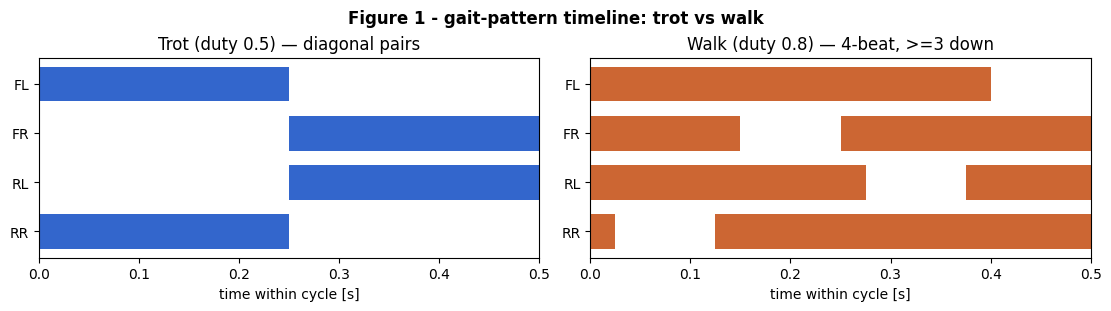

In [3]:
def gait_diagram(ax, C, ts, title, color):
    n = C.shape[1]
    for i in range(n):
        on = C[:, i] > 0.5
        # Draw contiguous stance runs as bars.
        dt = ts[1] - ts[0]
        for k in range(len(ts)):
            if on[k]:
                ax.barh(
                    n - 1 - i, dt, left=ts[k], height=0.7, color=color, edgecolor="none"
                )
    ax.set_yticks(range(n))
    ax.set_yticklabels(list(reversed(FEET)))
    ax.set_xlabel("time within cycle [s]")
    ax.set_title(title)
    ax.set_xlim(0, ts[-1] + (ts[1] - ts[0]))


fig, axes = plt.subplots(1, 2, figsize=(11, 3.0), constrained_layout=True)
gait_diagram(
    axes[0], contact["trot"], ts, "Trot (duty 0.5) — diagonal pairs", "#3366cc"
)
gait_diagram(
    axes[1], contact["walk"], ts, "Walk (duty 0.8) — 4-beat, >=3 down", "#cc6633"
)
fig.suptitle("Figure 1 - gait-pattern timeline: trot vs walk", fontweight="bold")
plt.show()

**Gate — trot diagonal alternation.** The defining property of a trot is
that the two diagonals are in anti-phase: when $\{$FL, RR$\}$ is in stance,
$\{$FR, RL$\}$ is in swing, and vice versa. With duty exactly $0.5$ they tile
the cycle with no overlap and no gap.

In [4]:
trot_C = contact["trot"]
diagA = trot_C[:, [0, 3]].all(axis=1)  # FL & RR down
diagB = trot_C[:, [1, 2]].all(axis=1)  # FR & RL down

# Sample two phases: one inside each diagonal's stance window.
ca = np.asarray(gaits["trot"].contact(0.1 * T))  # diagonal A
cb = np.asarray(gaits["trot"].contact(0.6 * T))  # diagonal B
print("trot @ 0.1T:", ca.astype(int), "(expect FL,RR down)")
print("trot @ 0.6T:", cb.astype(int), "(expect FR,RL down)")

assert ca[0] and ca[3] and not ca[1] and not ca[2], "diagonal A signature"
assert cb[1] and cb[2] and not cb[0] and not cb[3], "diagonal B signature"
assert np.all(diagA != diagB), "diagonals must alternate (never both, never neither)"
assert int(trot_C.sum(axis=1).min()) == 2 and int(trot_C.sum(axis=1).max()) == 2, (
    "trot keeps exactly two feet down at duty 0.5"
)
print("PASS: trot is a clean diagonal alternation, two-foot support throughout.")

trot @ 0.1T: [1 0 0 1] (expect FL,RR down)
trot @ 0.6T: [0 1 1 0] (expect FR,RL down)
PASS: trot is a clean diagonal alternation, two-foot support throughout.


**Gate — walk static-stability margin.** A statically stable gait keeps the
support polygon non-degenerate at all times: at least three feet down so the CoM
projection can lie inside a triangle. We verify the walk never drops below three
stance feet.

In [5]:
walk_nstance = contact["walk"].sum(axis=1)
print(
    "walk stance-feet count over the cycle: "
    f"min={int(walk_nstance.min())}, mean={walk_nstance.mean():.2f}, "
    f"max={int(walk_nstance.max())}"
)
assert int(walk_nstance.min()) >= 3, "walk must keep >=3 feet down (static stability)"
print("PASS: walk maintains a >=3-foot support set throughout the cycle.")

walk stance-feet count over the cycle: min=3, mean=3.20, max=4
PASS: walk maintains a >=3-foot support set throughout the cycle.


### Figure 2 — number of stance feet vs time (all four families)

Plotting the stance-foot *count* over a cycle separates the families at a glance:
walk hovers at 3-4 (statically stable); trot, pace, and bound sit flat at 2
(dynamically stable two-contact support). Note none of these drop to **zero** —
that would be a flight phase, which appears only at lower duty (we return to it
under *Failure modes*).

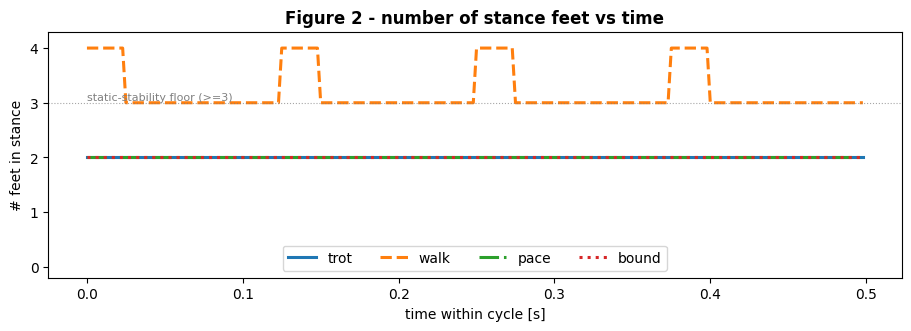

In [6]:
fig, ax = plt.subplots(figsize=(9, 3.2), constrained_layout=True)
styles = {"trot": "-", "walk": "--", "pace": "-.", "bound": ":"}
for name, C in contact.items():
    ax.plot(ts, C.sum(axis=1), styles[name], lw=2.2, label=name)
ax.axhline(3, color="grey", lw=0.8, ls=":", alpha=0.7)
ax.text(0.0, 3.05, "static-stability floor (>=3)", fontsize=8, color="grey")
ax.set_xlabel("time within cycle [s]")
ax.set_ylabel("# feet in stance")
ax.set_ylim(-0.2, 4.3)
ax.set_yticks([0, 1, 2, 3, 4])
ax.set_title("Figure 2 - number of stance feet vs time", fontweight="bold")
ax.legend(ncol=4, loc="lower center")
plt.show()

## 2. The schedule gates the whole-body QP

Now the payoff: wiring the schedule into the controller. Recall from Part 3 that
a foot in contact must not accelerate — its contact point obeys
$J_c\,\ddot q + \dot J_c\,\dot q = 0$, which the WBC enters as a high-weight task
$J_c\,\ddot q \approx -\dot J_c\,\dot q$. A `ContactTask` carries an **`active`
gate** $\alpha \in [0, 1]$ that scales the task's rows by $\sqrt{\alpha}$:

$$
\tilde J = \sqrt{\alpha}\,J_c, \qquad \tilde r = \sqrt{\alpha}\,(-\dot J_c\,\dot q),
$$

so $\alpha = 1$ is a near-hard contact constraint and $\alpha = 0$ removes the
task from the QP entirely. A swing foot is exactly $\alpha = 0$.

`contact_tasks_from_schedule(model, foot_ids, schedule, t)` does the join: it
samples `schedule.contact(t)`, and for each foot builds a `ContactTask` whose
`active` gate **is** that boolean. The result is a task list where stance feet
constrain the QP and swing feet vanish — and crucially the *same* construction
works at every phase. We demonstrate on the **biped G1** (two feet:
`left_ankle_roll_link`, `right_ankle_roll_link`).

In [7]:
from jaxterity import zoo
from jaxterity.wbc.locomotion import (
    contact_tasks_from_schedule,
    foot_body_ids,
    stance_swing_masks,
)

robot = zoo.unitree_g1.load(floating_base=True)
FEET_G1 = ("left_ankle_roll_link", "right_ankle_roll_link")

# A biped "walk": each foot stands 60% of the cycle, the two anti-phase.
biped = periodic_gait(FEET_G1, period=0.6, duty=0.6, phases=(0.0, 0.5))

foot_ids = foot_body_ids(robot, FEET_G1)
model = robot.build_system()._mjx_model
print("G1 foot body ids:", foot_ids)
print("G1 nq/nv:", model.nq, model.nv)

G1 foot body ids: (7, 13)
G1 nq/nv: 36 35


At a chosen phase, the active gates of the generated tasks must exactly
reproduce the schedule's contact mask. We sample several phases across the cycle
— including the single-support windows where one foot is swinging — and confirm
the gate tracks the schedule.

In [8]:
phases = [0.0, 0.10, 0.20, 0.30, 0.45, 0.55]
rows = []
ok = True
for t in phases:
    sched = np.asarray(biped.contact(t)).astype(int)
    tasks = contact_tasks_from_schedule(model, foot_ids, biped, t)
    active = np.array([round(tk.active) for tk in tasks]).astype(int)
    stance, swing = stance_swing_masks(biped, t)
    rows.append(
        (t, sched.tolist(), active.tolist(), np.asarray(swing).astype(int).tolist())
    )
    ok = ok and np.array_equal(sched, active)

print(f"{'t':>5} | {'schedule(L,R)':>14} | {'task active':>12} | {'swing':>8}")
print("-" * 48)
for t, s, a, sw in rows:
    print(f"{t:>5.2f} | {str(s):>14} | {str(a):>12} | {str(sw):>8}")

assert ok, "ContactTask.active must equal schedule.contact(t) at every phase"
# stance/swing must be exact complements.
t = 0.1
stance, swing = stance_swing_masks(biped, t)
assert np.all(np.asarray(stance) == np.asarray(biped.contact(t)))
assert np.all(np.asarray(swing) == ~np.asarray(biped.contact(t)).astype(bool))
print(
    "\nPASS: the contact-task active gates track the schedule; "
    "swing = complement of stance."
)

    t |  schedule(L,R) |  task active |    swing
------------------------------------------------
 0.00 |         [1, 1] |       [1, 1] |   [0, 0]
 0.10 |         [1, 0] |       [1, 0] |   [0, 1]
 0.20 |         [1, 0] |       [1, 0] |   [0, 1]
 0.30 |         [1, 1] |       [1, 1] |   [0, 0]
 0.45 |         [0, 1] |       [0, 1] |   [1, 0]
 0.55 |         [0, 1] |       [0, 1] |   [1, 0]

PASS: the contact-task active gates track the schedule; swing = complement of stance.


### Figure 3 — stance/swing mask over a cycle (the QP's contact set)

The same information as a picture: for each G1 foot, a green band where its
contact task is **active** (stance → in the QP) and an empty gap where it is
swing (dropped from the QP). The dashed line marks the single phase the table
above sampled at $t=0.30\,$s of a $0.6\,$s cycle. This is *literally* the set of
contact constraints the WBC solves at each instant — the gait makes it sweep.

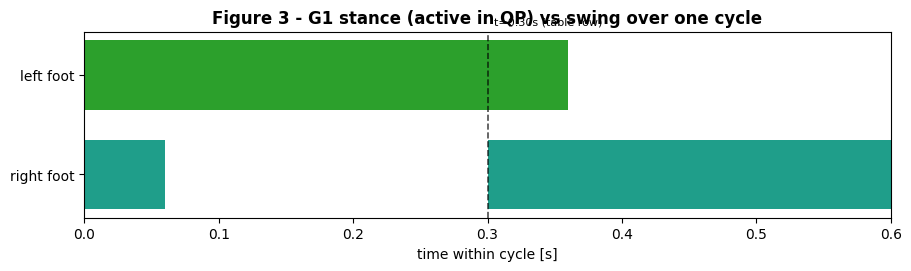

In [9]:
cyc = np.linspace(0.0, biped.period, 240, endpoint=False)
Cg = np.stack([np.asarray(biped.contact(float(t))) for t in cyc])  # (240, 2)

fig, ax = plt.subplots(figsize=(9, 2.6), constrained_layout=True)
labels = ["left foot", "right foot"]
colors = ["#2ca02c", "#1f9e8a"]
dt = cyc[1] - cyc[0]
for i in range(2):
    for k in range(len(cyc)):
        if Cg[k, i] > 0.5:
            ax.barh(
                1 - i, dt, left=cyc[k], height=0.7, color=colors[i], edgecolor="none"
            )
ax.axvline(0.30, color="k", ls="--", lw=1.2, alpha=0.7)
ax.text(0.305, 1.5, "t=0.30s (table row)", fontsize=8)
ax.set_yticks([0, 1])
ax.set_yticklabels(["right foot", "left foot"])
ax.set_xlabel("time within cycle [s]")
ax.set_title(
    "Figure 3 - G1 stance (active in QP) vs swing over one cycle", fontweight="bold"
)
ax.set_xlim(0, cyc[-1] + dt)
plt.show()

## 3. A dynamic walk — the pretrained joystick baseline

So far everything is **model-based** and hand-specified: we wrote down a gait and
showed the WBC's contact set following it. To see a real, dynamic, balancing
walk — feet actually leaving and striking the ground, the base translating
forward — we roll out a **pretrained** policy.

> **Honesty note (please read).** The walk rendered below is produced by a
> *learned* neural-network joystick policy (`G1JoystickController`), vendored from
> MuJoCo Playground. It is **not** the output of the model-based WBC pipeline of
> Parts 2-3. The relationship is this: the model-based stack (reduced models →
> WBC → the gait scheduler above) supplies the *contact structure* — it tells you
> which feet should be down when and turns that into QP constraints — while this
> pretrained policy is shown as a *baseline dynamic walk* against which that
> structure can be read. We do **not** claim the WBC alone produced this gait.
> The honest framing: the scheduler defines the rhythm; the learned policy
> demonstrates a dynamic execution of one.

The controller builds its own MJX scene and policy; `rollout(command, n_steps)`
returns per-tick `qpos`/`qvel`. We command a steady forward walk
$[v_x, v_y, \omega_z] = [0.6, 0, 0]$ m/s and roll for 100 ticks (2.0 s; each tick
is 20 ms = 10 physics substeps).

In [10]:
from jaxterity.locomotion.g1_joystick import G1JoystickController, load_walk_model

controller = G1JoystickController()
command = jnp.array([0.6, 0.0, 0.0])  # v_x, v_y, omega_z
N_TICKS = 100  # 2.0 s
roll = controller.rollout(command, N_TICKS)

qpos = np.asarray(roll.qpos)  # (N, 36): [x,y,z, quat(4), 29 joints]
base_x = qpos[:, 0]
base_y = qpos[:, 1]
base_z = qpos[:, 2]
t_roll = np.arange(N_TICKS) * 0.02

dx = float(base_x[-1] - base_x[0])
print(
    f"base x: {base_x[0]:.3f} -> {base_x[-1]:.3f} m  (forward progress dx={dx:.3f} m)"
)
print(f"base z (height): mean={base_z.mean():.3f}, min={base_z.min():.3f} m")

assert dx > 0.2, "the joystick rollout must advance the base forward"
assert base_z.min() > 0.4, "the robot must stay upright (base height not collapsing)"
print("PASS: the pretrained policy produces a forward-progressing, upright walk.")

base x: 0.001 -> 1.052 m  (forward progress dx=1.051 m)
base z (height): mean=0.745, min=0.709 m
PASS: the pretrained policy produces a forward-progressing, upright walk.


**Rendering.** The vendored *locomotion* scene the policy runs in is
mesh-free (a floor and two foot collision boxes — all the physics needs), so it
does not make a presentable picture. We therefore replay the rollout's `qpos(t)`
through the full-mesh G1 **showcase scene** (`examples/assets/unitree_g1_mjcf/`)
using the project's post-hoc `TrajectoryRenderer`: MuJoCo does *no physics* here,
it just sets each pose and renders the meshes, mapping the walk-scene `qpos`
layout onto the showcase scene. We save a looping GIF under `examples/media/` and
show a frame strip (Figure 4). The base-trajectory / foot-height plot (Figure 5)
is shown regardless and quantifies the same forward walk, so the qualitative and
quantitative views agree even if a machine cannot render.

In [11]:
import pathlib
import sys

sys.path.insert(0, str(pathlib.Path.cwd()))  # for _robot_render
import _robot_render as rr

from jaxterity.locomotion.g1_joystick import WALK_MJCF_PATH

# The rollout qpos is in the *walk-scene* layout; give that as the src model so
# the renderer remaps each joint onto the full-mesh showcase scene.
src_mjcf = WALK_MJCF_PATH.read_text()
traj_renderer = rr.TrajectoryRenderer("unitree_g1_mjcf", src_mjcf, size=(480, 360))

camera = {
    "distance": 3.0,
    "azimuth": 120.0,
    "elevation": -10.0,
    "lookat": [0.5, 0.0, 0.6],
}
frames = traj_renderer.render(qpos, camera=camera, stride=2)  # ~50 frames
frames = [np.asarray(f) for f in frames]
mid = frames[len(frames) // 2]
print(
    "rendered",
    len(frames),
    "frames, each",
    frames[0].shape,
    "| mid-frame std =",
    round(float(mid.std()), 1),
)
assert frames[0].shape == (360, 480, 3) and mid.std() > 5, (
    "frames must be non-trivial (the meshed robot is in view)"
)
print("PASS: post-hoc mesh render produced non-trivial frames.")

rendered 50 frames, each (360, 480, 3) | mid-frame std = 35.1
PASS: post-hoc mesh render produced non-trivial frames.


In [12]:
# Save a looping GIF under examples/media/ via the project's writer (imageio).
media = pathlib.Path("media")
media.mkdir(exist_ok=True)
gif_path = media / "locomotion_part_4_walk.gif"
rr.write_gif(frames, str(gif_path), width=480, fps=15)

# Sanity-check the written GIF: frame count and visible motion.
from PIL import Image, ImageSequence  # noqa: E402

check = Image.open(gif_path)
arrs = np.asarray(
    [np.asarray(fr.convert("RGB")) for fr in ImageSequence.Iterator(check)]
)
motion = float(np.abs(np.diff(arrs.astype(int), axis=0)).mean())
print(
    "saved GIF ->",
    gif_path,
    "| frames:",
    arrs.shape[0],
    "| bytes:",
    gif_path.stat().st_size,
    "| inter-frame motion:",
    round(motion, 3),
)
assert gif_path.exists() and gif_path.stat().st_size > 5000, "GIF should be non-trivial"
assert arrs.shape[0] >= 10, "GIF must keep the rollout frames"
assert motion > 0.3, "GIF frames must show the robot moving"
print("PASS: looping walking GIF saved with visible motion.")

saved GIF -> media/locomotion_part_4_walk.gif | frames: 50 | bytes: 2864558 | inter-frame motion: 1.657
PASS: looping walking GIF saved with visible motion.


### Figure 4 — rendered walking strip (pretrained joystick policy)

Six frames across the 2-second rollout, left to right. The G1 strides forward
across the checkered floor — swing leg advancing, base translating — the dynamic
execution the *learned* policy provides. (The full looping GIF was saved to
`examples/media/locomotion_part_4_walk.gif`.)

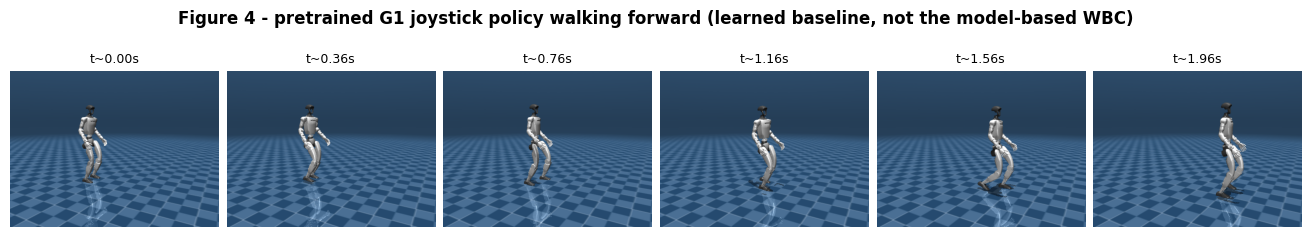

In [13]:
strip_k = np.linspace(0, len(frames) - 1, 6).astype(int)

fig, axes = plt.subplots(1, 6, figsize=(13, 2.6), constrained_layout=True)
for ax, k in zip(axes, strip_k):
    ax.imshow(frames[k])
    ax.axis("off")
    # frames were strided by 2 over N_TICKS ticks at 0.02 s each.
    ax.set_title(f"t~{k * 2 * 0.02:.2f}s", fontsize=9)
fig.suptitle(
    "Figure 4 - pretrained G1 joystick policy walking forward "
    "(learned baseline, not the model-based WBC)",
    fontweight="bold",
)
plt.show()

### Figure 5 — base trajectory & foot height (the same walk, quantified)

The render is qualitative; this is the measurement. Left: the base advances
monotonically in $x$ while its height $z$ oscillates gently at the step cadence
(the body bobs once per step) — exactly the forward progress the gate asserted.
Right: the two ankle-roll bodies' heights over time, read from MJX forward
kinematics — their alternating lift-offs are the *learned* gait's actual
stance/swing pattern, the empirical analogue of the schedule in Figure 3.

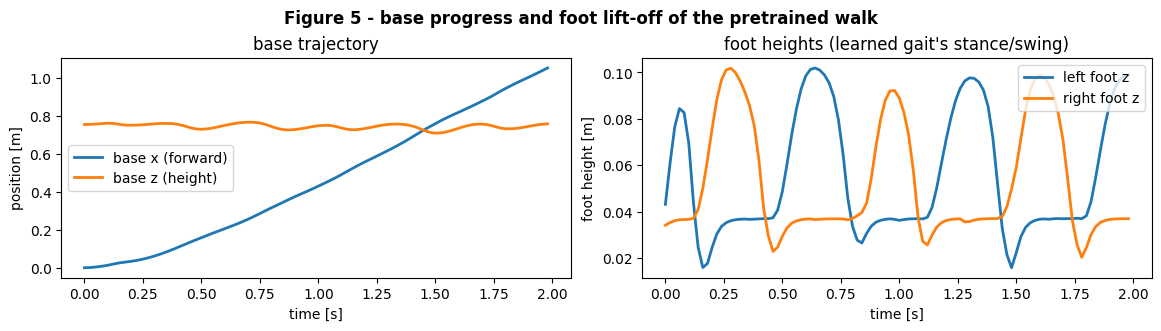

forward speed (mean) = 0.531 m/s (commanded 0.60 m/s)


In [14]:
# Foot world heights along the rollout, via MuJoCo FK on the walk scene
# (whose qpos layout the rollout uses).
import mujoco

m = load_walk_model()
d = mujoco.MjData(m)
lf_id = m.body("left_ankle_roll_link").id
rf_id = m.body("right_ankle_roll_link").id
lf_z, rf_z = [], []
for k in range(N_TICKS):
    d.qpos[:] = qpos[k]
    mujoco.mj_forward(m, d)
    lf_z.append(float(d.xpos[lf_id, 2]))
    rf_z.append(float(d.xpos[rf_id, 2]))
lf_z = np.array(lf_z)
rf_z = np.array(rf_z)

fig, (axL, axR) = plt.subplots(1, 2, figsize=(11.5, 3.2), constrained_layout=True)
axL.plot(t_roll, base_x, lw=2, label="base x (forward)")
axL.plot(t_roll, base_z, lw=2, label="base z (height)")
axL.set_xlabel("time [s]")
axL.set_ylabel("position [m]")
axL.set_title("base trajectory")
axL.legend(loc="center left")

axR.plot(t_roll, lf_z, lw=2, label="left foot z")
axR.plot(t_roll, rf_z, lw=2, label="right foot z")
axR.set_xlabel("time [s]")
axR.set_ylabel("foot height [m]")
axR.set_title("foot heights (learned gait's stance/swing)")
axR.legend(loc="upper right")
fig.suptitle(
    "Figure 5 - base progress and foot lift-off of the pretrained walk",
    fontweight="bold",
)
plt.show()

print(
    f"forward speed (mean) = {dx / (t_roll[-1] - t_roll[0]):.3f} m/s "
    f"(commanded {float(command[0]):.2f} m/s)"
)

## Failure modes

**Too-short duty → flight phase, and the LIP/QS assumptions break.** Drop the
duty below the point where stances overlap and the gait develops a **flight
phase**: an interval with *zero* feet on the ground. Two things break there.
(i) The whole-body QP loses all contact rows — with no foot constraining the
floating base, the under-actuated base directions are unsupported and the QP
solution is no longer a valid stance controller for that interval. (ii) The
reduced models from Part 1 stop applying: the **Linear Inverted Pendulum** assumes
a pivot foot in contact, and the **quasi-static** (QS) assumption assumes the CoM
projection stays inside a non-empty support polygon. In flight, the only honest
model is ballistic — $\ddot c = g$ — and contact-schedule planning must treat the
flight interval explicitly. The cell below shows duty $0.35$ on a trot producing
flight (stance-feet count touching 0).

In [15]:
flighty = periodic_gait(FEET, period=T, duty=0.35, phases=(0.0, 0.5, 0.5, 0.0))
Cf = np.stack([np.asarray(flighty.contact(float(t))) for t in ts])
nmin = int(Cf.sum(axis=1).min())
print(f"trot @ duty 0.35: min stance feet over cycle = {nmin}")
if nmin == 0:
    frac_flight = float((Cf.sum(axis=1) == 0).mean())
    print(
        f"  -> FLIGHT PHASE present for {frac_flight * 100:.0f}% of the cycle. "
        "LIP/QS assumptions invalid here; QP has no contact rows."
    )
assert nmin == 0, "this duty is meant to illustrate a flight phase"
print("(Contrast: the duty-0.8 walk above never drops below 3 — no flight.)")

trot @ duty 0.35: min stance feet over cycle = 0
  -> FLIGHT PHASE present for 30% of the cycle. LIP/QS assumptions invalid here; QP has no contact rows.
(Contrast: the duty-0.8 walk above never drops below 3 — no flight.)


**Contact-switch chatter.** Because `contact(t)` is a hard boolean
threshold at $\phi = d$, a foot's task gate flips $0 \leftrightarrow 1$
discontinuously at touchdown/lift-off. If the controller re-solves at a rate
comparable to the switching, or if a foot's true phase dithers around the
threshold (sensor noise, a phase estimator near a boundary), the contact set can
**chatter** — toggling a task in and out on successive ticks. The torque
solution jumps with it, exciting the actuators and, on hardware, audible/visible
buzzing at the feet. Mitigations live outside this notebook's scope but are worth
naming: a minimum dwell time per contact state, a small hysteresis band around
$\phi = d$, or smoothing the gate (ramp $\alpha$ over a few ms instead of a step).
Below we count how many switch events a clean schedule has per cycle — the floor
you would compare a noisy estimator against.

In [16]:
def switch_count(C):
    # transitions per foot summed over the cycle (wrap-around included).
    Cw = np.vstack([C, C[:1]])
    return int(np.abs(np.diff(Cw.astype(int), axis=0)).sum())


for name, C in contact.items():
    print(
        f"{name:6s}: {switch_count(C)} contact switch events / cycle "
        f"({switch_count(C) // 2} touchdowns + lift-offs per foot-pair-ish)"
    )
print(
    "\nA phase estimator dithering across phi=d would *add* spurious "
    "switches on top of these — that surplus is the chatter to suppress."
)

trot  : 8 contact switch events / cycle (4 touchdowns + lift-offs per foot-pair-ish)
walk  : 8 contact switch events / cycle (4 touchdowns + lift-offs per foot-pair-ish)
pace  : 8 contact switch events / cycle (4 touchdowns + lift-offs per foot-pair-ish)
bound : 8 contact switch events / cycle (4 touchdowns + lift-offs per foot-pair-ish)

A phase estimator dithering across phi=d would *add* spurious switches on top of these — that surplus is the chatter to suppress.


## Exercises

1. **Amble vs walk.** Build a quadruped *amble* (a fast walk, duty $\approx 0.6$,
   phases $(0, 0.5, 0.25, 0.75)$) and plot its stance-feet count. At what duty
   does it lose the $\geq 3$ static-stability property and become a dynamic gait?

2. **Pace vs trot signature.** Reproduce the Figure-1 gait diagram for pace and
   bound. Which has lateral pairs in phase, which has front/rear? Verify your
   answer against the schedule like the trot gate does.

3. **Duty sweep.** For a trot, sweep duty from $0.3$ to $0.7$ and plot the
   fraction of the cycle spent in a flight phase (zero feet). Mark the duty at
   which flight first disappears.

4. **Phase-offset gate.** Shift the G1 biped's right-foot phase from $0.5$ to
   $0.3$ and rebuild the contact tasks across a cycle. How does the
   double-support overlap change, and what does that do to the count of phases
   where both contact tasks are active simultaneously?

5. **Hysteresis.** Wrap `schedule.contact` in a thin stateful hysteresis (latch
   the previous state within a band $\pm\epsilon$ of $\phi = d$) and show it
   removes the surplus switches that a noisy phase signal would introduce.


## References

- M. H. Raibert, *Legged Robots That Balance*, MIT Press, 1986. The origin of
  treating locomotion as the management of contact timing and a small set of
  reduced-order behaviours.
- J. Di Carlo, P. M. Wensing, B. Katz, G. Bledt, S. Kim, "Dynamic Locomotion in
  the MIT Cheetah 3 Through Convex Model-Predictive Control," *IROS*, 2018. The
  convex-MPC gait/contact-force optimiser that *plans* the schedule online —
  the natural next rung above the hand-specified schedule used here.
- N. Rudin et al. / MuJoCo Playground (`google-deepmind/mujoco_playground`).
  Source of the vendored Unitree G1 joystick locomotion policy and scene used
  for the dynamic-walk baseline in §3 (Apache-2.0).
- Earlier in this series: Part 1 (reduced models: SRBD, LIP, capture point),
  Part 2 (footstep planning), Part 3 (whole-body control QP).


## Next steps

The schedule here is **given**. Part 5 makes it a **decision variable**: a
per-stage / receding-horizon contact-and-force optimiser (in the spirit of
Di Carlo et al. 2018) that *chooses* the gait — touchdown timing, stance forces,
and the resulting CoM trajectory — subject to friction-cone and kinematic limits,
and hands the optimised schedule to exactly the WBC-gating machinery of §2. That
closes the model-based loop end-to-end: plan the contacts, gate the QP, track on
hardware — and replaces the learned baseline of §3 with a model-based dynamic
walk you can attest and deploy through Jaxility.

**→ Continue to Part 5: planning the gait (contact-schedule MPC).**
